Attendance Fraud Detection: VAE vs One-Class SVM

This notebook keeps the experiment simple.

We will:
- load the 1,250-row attendance dataset
- prepare useful attendance, location, phone and network features
- train One-Class SVM using normal attendance only
- train a small Variational Autoencoder (VAE) using normal attendance only
- test both on the same labelled test set
- compare precision, recall and F1 score


In [1]:
# libraries

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve
)

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# use the same random seed each time
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch version:", torch.__version__)


PyTorch version: 2.14.1


1. Load the dataset

In [2]:
# load the csv file

from pathlib import Path

csv_path = Path("unified_attendance_1250.csv")

if not csv_path.exists():
    csv_path = Path("/mnt/data/unified_attendance_1250.csv")

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1250, 32)


,attendance_id,employee_id,job_id,site_id,clock_in_at,clock_out_at,shift_hours,break_minutes,paid_hours,payroll_variance_hours,...,travel_speed_kmh,device_id,phone_manufacturer,phone_model,phone_os,phone_os_version,network_type,network_changed_flag,device_shared_flag,fraud_label
0,AT5C21671A8A0AB,E0001,JOB0028,SITE010,2024-11-08T08:35+05:30,2024-11-08T16:50+05:30,8.2500,30.0,7.7500,0.0,...,64.38,DEV0001,Samsung,Galaxy S22,Android,14,5G,0,0,0.0
1,AT2CD4AE425E0F2,E0013,JOB0001,SITE012,2025-10-12T09:05+05:30,2025-10-12T12:55+05:30,3.8333,0.0,3.8333,0.0,...,28.89,DEV0013,Samsung,Galaxy S22,Android,14,WiFi,0,0,0.0
2,AT72D10B16C8F7E,E0014,JOB0028,SITE010,2025-04-03T08:45+05:30,2025-04-03T17:15+05:30,8.5000,30.0,8.0000,0.0,...,18.68,DEV0023,Samsung,Galaxy A34,Android,14,WiFi,1,0,0.0
3,ATF600BB896C1B3,E0004,JOB0058,SITE005,2025-05-24T07:36+05:30,2025-05-24T15:41+05:30,8.0833,30.0,7.5833,0.0,...,17.84,DEV0029,Xiaomi,Redmi Note 13,Android,14,4G,0,0,0.0
4,ATB1FBD482D62E6,E0001,JOB0056,SITE001,2024-06-25T09:30+05:30,2024-06-25T17:30+05:30,8.0000,30.0,7.5000,0.0,...,13.64,DEV0001,Samsung,Galaxy S22,Android,14,4G,0,0,NaN


In [3]:
# check the fraud labels

print(df["fraud_label"].value_counts(dropna=False))

labelled_rows = df["fraud_label"].notna().sum()
unlabelled_rows = df["fraud_label"].isna().sum()

print("\nLabelled rows:", labelled_rows)
print("Unlabelled rows:", unlabelled_rows)


fraud_label
0.0    820
NaN    250
1.0    180
Name: count, dtype: int64

Labelled rows: 1000
Unlabelled rows: 250


2. Prepare the features

In [4]:
# add simple time features

df["clock_in_at"] = pd.to_datetime(df["clock_in_at"], errors="coerce")
df["clock_in_hour"] = df["clock_in_at"].dt.hour + df["clock_in_at"].dt.minute / 60
df["clock_in_day_of_week"] = df["clock_in_at"].dt.dayofweek

numeric_features = [
    "shift_hours",
    "break_minutes",
    "paid_hours",
    "payroll_variance_hours",
    "previous_shift_gap_hours",
    "has_previous_shift",
    "clock_out_estimated",
    "distance_to_site_m",
    "geofence_radius_m",
    "gps_accuracy_m",
    "mock_location_flag",
    "travel_speed_kmh",
    "phone_os_version",
    "network_changed_flag",
    "device_shared_flag",
    "clock_in_hour",
    "clock_in_day_of_week"
]

categorical_features = [
    "geofence_status",
    "phone_manufacturer",
    "phone_model",
    "phone_os",
    "network_type"
]

# use labelled rows for the comparison
model_df = df[df["fraud_label"].notna()].copy()
model_df["fraud_label"] = model_df["fraud_label"].astype(int)

X = model_df[numeric_features + categorical_features]
y = model_df["fraud_label"]

print("Rows used for comparison:", len(model_df))
print("\nClass counts:")
print(y.value_counts())


Rows used for comparison: 1000

Class counts:
fraud_label
0    820
1    180
Name: count, dtype: int64


3. Train/test split

In [5]:
# split the same data for both models

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

# train only with normal records
X_train_normal = X_train[y_train == 0].copy()

print("Normal rows used for training:", len(X_train_normal))
print("Test rows:", len(X_test))
print("\nTest labels:")
print(y_test.value_counts())


Normal rows used for training: 574
Test rows: 300

Test labels:
fraud_label
0    246
1     54
Name: count, dtype: int64


4. Clean and scale the data

In [6]:
# fill missing numeric values
for col in numeric_features:
    median_value = X_train_normal[col].median()
    X_train_normal[col] = X_train_normal[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

# fill missing text values
for col in categorical_features:
    X_train_normal[col] = X_train_normal[col].fillna("unknown")
    X_test[col] = X_test[col].fillna("unknown")

# encode text and scale numbers
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", encoder, categorical_features)
    ]
)

X_train_ready = preprocessor.fit_transform(X_train_normal)
X_test_ready = preprocessor.transform(X_test)

X_train_ready = np.asarray(X_train_ready, dtype=np.float32)
X_test_ready = np.asarray(X_test_ready, dtype=np.float32)

print("Prepared training shape:", X_train_ready.shape)
print("Prepared test shape:", X_test_ready.shape)


Prepared training shape: (574, 41)
Prepared test shape: (300, 41)


5. One-Class SVM

In [7]:
# train one-class svm on normal records

ocsvm = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.05
)

ocsvm.fit(X_train_ready)

# convert svm output to 0 = normal and 1 = fraud
svm_raw_prediction = ocsvm.predict(X_test_ready)
svm_prediction = (svm_raw_prediction == -1).astype(int)

# higher value means more unusual
svm_anomaly_score = -ocsvm.decision_function(X_test_ready)

print("One-Class SVM finished.")


One-Class SVM finished.


6. Variational Autoencoder (VAE)

In [8]:
# simple vae

class VAE(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, latent_dim=8):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU()
        )

        self.mu = nn.Linear(hidden_dim, latent_dim)
        self.logvar = nn.Linear(hidden_dim, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim)
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.mu(h), self.logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decoder(z)
        return reconstructed, mu, logvar


def vae_loss(reconstructed, original, mu, logvar):
    reconstruction_loss = nn.functional.mse_loss(
        reconstructed, original, reduction="mean"
    )

    kl_loss = -0.5 * torch.mean(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return reconstruction_loss + 0.001 * kl_loss


In [9]:
# train the vae with normal records

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

train_tensor = torch.tensor(X_train_ready, dtype=torch.float32)
train_loader = DataLoader(
    TensorDataset(train_tensor),
    batch_size=32,
    shuffle=True
)

vae = VAE(input_dim=X_train_ready.shape[1]).to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=0.001)

epochs = 60
loss_history = []

vae.train()

for epoch in range(epochs):
    epoch_loss = 0.0

    for (batch,) in train_loader:
        batch = batch.to(device)

        optimizer.zero_grad()
        reconstructed, mu, logvar = vae(batch)

        loss = vae_loss(reconstructed, batch, mu, logvar)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * len(batch)

    epoch_loss /= len(train_loader.dataset)
    loss_history.append(epoch_loss)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:02d}/{epochs} - loss: {epoch_loss:.4f}")


Using: cpu
Epoch 10/60 - loss: 0.3179
Epoch 20/60 - loss: 0.2014
Epoch 30/60 - loss: 0.1444
Epoch 40/60 - loss: 0.1179
Epoch 50/60 - loss: 0.0985
Epoch 60/60 - loss: 0.0890


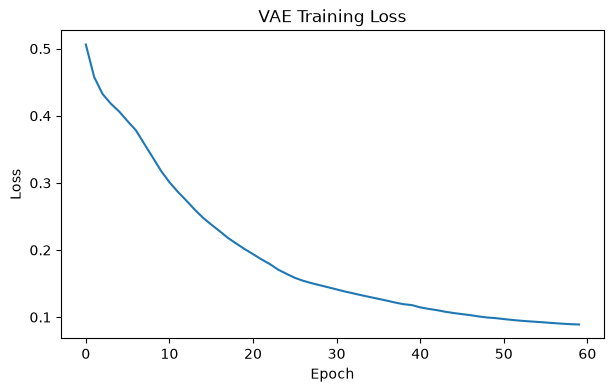

In [10]:
# show vae training loss

plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss")
plt.show()


In [11]:
# use reconstruction error as the anomaly score

def get_reconstruction_error(model, data_array):
    model.eval()

    data_tensor = torch.tensor(
        data_array,
        dtype=torch.float32,
        device=device
    )

    with torch.no_grad():
        # use the latent mean for stable scoring
        mu, logvar = model.encode(data_tensor)
        reconstructed = model.decoder(mu)

        error = torch.mean(
            (data_tensor - reconstructed) ** 2,
            dim=1
        )

    return error.cpu().numpy()


train_error = get_reconstruction_error(vae, X_train_ready)
test_error = get_reconstruction_error(vae, X_test_ready)

# flag values above the normal training threshold
vae_threshold = np.percentile(train_error, 95)

vae_prediction = (test_error > vae_threshold).astype(int)

print("VAE threshold:", round(float(vae_threshold), 4))
print("VAE finished.")


VAE threshold: 0.1829
VAE finished.


7. Compare the two models

In [12]:
def model_metrics(name, actual, predicted, scores):
    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1 Score": f1_score(actual, predicted, zero_division=0),
        "ROC AUC": roc_auc_score(actual, scores),
        "PR AUC": average_precision_score(actual, scores)
    }


results = pd.DataFrame([
    model_metrics(
        "One-Class SVM",
        y_test,
        svm_prediction,
        svm_anomaly_score
    ),
    model_metrics(
        "VAE",
        y_test,
        vae_prediction,
        test_error
    )
])

results = results.set_index("Model")
display(results.round(4))


,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
Model,,,,,,
One-Class SVM,0.81,0.4819,0.7407,0.5839,0.8522,0.6000
VAE,0.83,0.5185,0.7778,0.6222,0.8795,0.6245


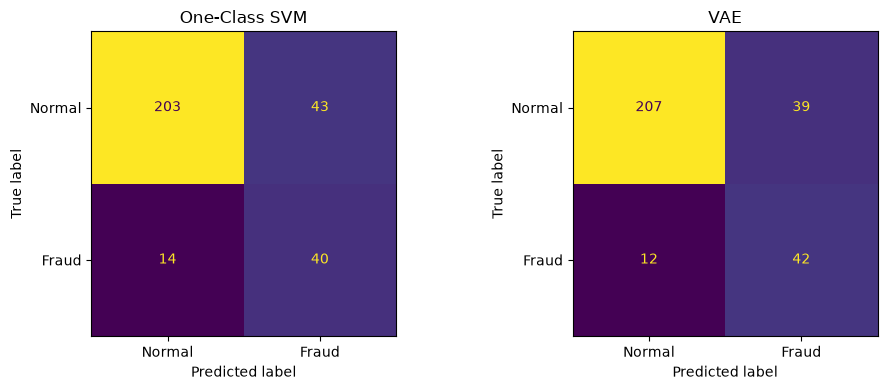

In [13]:
# show confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, svm_prediction),
    display_labels=["Normal", "Fraud"]
).plot(ax=axes[0], colorbar=False)

axes[0].set_title("One-Class SVM")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, vae_prediction),
    display_labels=["Normal", "Fraud"]
).plot(ax=axes[1], colorbar=False)

axes[1].set_title("VAE")

plt.tight_layout()
plt.show()


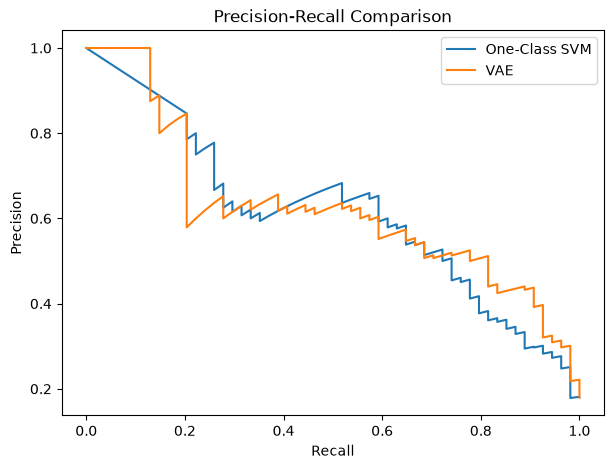

In [14]:
# compare precision and recall

svm_precision, svm_recall, _ = precision_recall_curve(
    y_test, svm_anomaly_score
)

vae_precision, vae_recall, _ = precision_recall_curve(
    y_test, test_error
)

plt.figure(figsize=(7, 5))
plt.plot(svm_recall, svm_precision, label="One-Class SVM")
plt.plot(vae_recall, vae_precision, label="VAE")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Comparison")
plt.legend()
plt.show()


8. Which one did better?

In [15]:
winner = results["F1 Score"].idxmax()

print(f"Better model based on F1 score: {winner}")
print(f"F1 score: {results.loc[winner, 'F1 Score']:.4f}")

display(results.round(4))


Better model based on F1 score: VAE
F1 score: 0.6222


,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
Model,,,,,,
One-Class SVM,0.81,0.4819,0.7407,0.5839,0.8522,0.6000
VAE,0.83,0.5185,0.7778,0.6222,0.8795,0.6245


Result from this run

The VAE performed better on this test split based on F1 score.

The VAE reached an F1 score of 0.6222, while the One-Class SVM reached 0.5839. The VAE also had higher precision, recall, ROC AUC and PR AUC in this run.

VAE results: accuracy 0.8300, precision 0.5185, recall 0.7778, F1 0.6222, ROC AUC 0.8795, PR AUC 0.6245.

One-Class SVM results: accuracy 0.8100, precision 0.4819, recall 0.7407, F1 0.5839, ROC AUC 0.8522, PR AUC 0.6000.

For this experiment, the VAE is therefore the better of the two models. These results apply to this dataset and test split and should not be treated as final production performance.
